# Exploración de candidatos a hallazgos

Cruces exploratorios sobre la colección de 228 anuncios. No son pruebas causales ni resultados confirmatorios: se han examinado múltiples comparaciones. Los grupos pueden compartir registros y la disponibilidad de datos no es aleatoria. Ejecutar desde la raíz del repositorio o desde notebooks/.

Se prueban razones concomitantes, funciones afectadas, proporción de plantilla recortada, atribución, anuncios repetidos e historia de plantilla. Las proporciones se toman como están registradas; falta una auditoría específica de sus denominadores antes de convertir el contraste de magnitud en hallazgo editorial. El alcance `announced_reduction` excluye planes de varios años, pero no garantiza por sí solo que cada porcentaje mida la misma unidad empresarial.

Base canónica SHA256: 320d1574191931cc392a6d5eb8294621975db58b18cc373132014dc9437d055e

In [1]:
import sqlite3,json,statistics
from collections import defaultdict,Counter
from pathlib import Path
ROOT=next(p for p in [Path.cwd(),Path.cwd().parent] if (p/'data/normalized/layoffs.sqlite').exists())
c=sqlite3.connect(ROOT/'data/normalized/layoffs.sqlite');c.row_factory=sqlite3.Row
records=[dict(r) for r in c.execute('select * from announcements')];byid={r['record_id']:r for r in records}
reasons=defaultdict(set);funcs=defaultdict(set);attributions=defaultdict(list)
for r in c.execute('select * from announcement_causes'):reasons[r['record_id']].add(r['cause_code']);attributions[r['cause_code']].append(dict(r))
for r in c.execute('select * from announcement_functions'):funcs[r['record_id']].add(r['function_code'])
ai_codes=sorted(x for x in attributions if x.startswith('ai_'))
print('AI CO-REASONS + WORK + SIZE + ATTRIBUTION')
for code in ai_codes:
 rows=[r for r in records if code in reasons[r['record_id']]];ids={r['record_id'] for r in rows}
 print('\n',code,'n',len(rows),'companies',len({r['company_label'] for r in rows}))
 print('co',Counter(x for i in ids for x in reasons[i] if not x.startswith('ai_')).most_common())
 print('functions coverage',sum(bool(funcs[i]) for i in ids),'functions',Counter(x for i in ids for x in funcs[i]).most_common())
 v=[r['workforce_fraction'] for r in rows if r['workforce_fraction'] is not None]
 print('fraction',len(v),'median',statistics.median(v) if v else None,'scope',Counter(r['headcount_scope'] for r in rows if r['workforce_fraction'] is not None))
 print('attribution',Counter(r['attribution'] for r in attributions[code]),'scope',Counter(r['scope'] for r in attributions[code]))
 print('public',sum(r['funding_stage']=='Post-IPO' for r in rows),'stages',Counter(r['funding_stage'] for r in rows))
 print('members',[(r['company_label'],r['workforce_fraction'],r['headcount_scope']) for r in rows])
print('\nHISTORY')
company_codes=defaultdict(set)
for r in records:company_codes[r['company_label']]|=reasons[r['record_id']]
hist=[]
for r in json.loads((ROOT/'research/hiring/company-history.json').read_text()):
 ep={y:max([o for o in r['observations'] if o['date'].startswith(str(y))],key=lambda o:o['date'],default=None) for y in [2019,2022,2025]}
 for a,b in [(2019,2022),(2022,2025)]:
  if ep[a] is None or ep[b] is None or ep[a]['value']<=0 or any(f'{a}_{b}' in x.get('exclude_windows',[]) for x in r['quality_issues']):continue
  hist.append(dict(company=r['company'],window=f'{a}_{b}',growth=100*(ep[b]['value']/ep[a]['value']-1),codes=sorted(company_codes[r['company']]),quality=r['quality_issues'],events=r['perimeter_events'],start=ep[a]['date'],end=ep[b]['date']))
for code in ai_codes:
 rr=[r for r in hist if code in r['codes'] and r['window']=='2022_2025']
 print(code,'n',len(rr),'median',statistics.median(r['growth'] for r in rr) if rr else None,'shrinking',sum(r['growth']<0 for r in rr))
 print([(r['company'],round(r['growth'],1)) for r in rr])
 for name,pred in [('no_perimeter',lambda r:not any(r['start']<e['date']<=r['end'] for e in r['events'])),('december',lambda r:r['start'][5:7]=='12' and r['end'][5:7]=='12'),('no_definition_issue',lambda r:not any(x.get('strict_exclusion') for x in r['quality']))]:
  sub=[r for r in rr if pred(r)];print(name,len(sub),statistics.median(r['growth'] for r in sub) if sub else None,sum(r['growth']<0 for r in sub))
print('\nOTHER REASONS SIZE (n>=7)')
for code in attributions:
 rr=[r for r in records if code in reasons[r['record_id']]];v=[r['workforce_fraction'] for r in rr if r['workforce_fraction'] is not None]
 if len(v)>=7: print(code,len(rr),len(v),round(statistics.median(v),3),Counter(r['headcount_scope'] for r in rr if r['workforce_fraction'] is not None))
print('\nREPEAT COMPANIES')
for co,n in Counter(r['company_label'] for r in records).items():
 if n>1:
  print(co,[(r['record_date'],sorted(reasons[r['record_id']])) for r in records if r['company_label']==co])
print('\nKNOWN FUNCTIONS BY GROUP')
for group in ['ai','other','none']:
 rr=[r for r in records if ('ai' if r['has_ai_reason'] else 'other' if r['reason_count'] else 'none')==group]
 print(group,len(rr),sum(bool(funcs[r['record_id']]) for r in rr),Counter(f for r in rr for f in funcs[r['record_id']]))



AI CO-REASONS + WORK + SIZE + ATTRIBUTION

 ai_investment_reallocation n 25 companies 23
co [('strategic_pivot', 7), ('cost_cutting', 6), ('organizational_consolidation', 5), ('unit_closure', 2), ('organizational_realignment', 2), ('work_relocation', 1)]
functions coverage 6 functions [('engineering', 3), ('marketing', 3), ('product_design', 2), ('corporate', 2), ('sales', 2), ('content', 1), ('people', 1), ('support', 1), ('it_security', 1), ('operations', 1)]
fraction 20 median 0.12000000000000001 scope Counter({'announced_reduction': 16, 'announced_plan': 4})
attribution Counter({'company_stated': 19, 'press_reported': 6}) scope Counter({'event': 19, 'announced_plan': 6})
public 12 stages Counter({'Post-IPO': 12, None: 9, 'Series C': 1, 'Acquired': 1, 'Series D': 1, 'Series B': 1})
members [('Hailo', 0.1, 'announced_reduction'), ('Meta', 0.02, 'announced_reduction'), ('Autodesk', 0.07, 'announced_reduction'), ('Pinterest', 0.15, 'announced_reduction'), ('Envato', 0.3, 'announced_red

## Comprobaciones adicionales de composición y alcance

In [2]:
for code in ['ai_productivity','ai_investment_reallocation']:
 rows=[r for r in records if code in reasons[r['record_id']] and r['workforce_fraction'] is not None and r['headcount_scope']=='announced_reduction']
 print(code, 'Anuncios puntuales con proporción disponible:',len(rows),'mediana:',statistics.median(r['workforce_fraction'] for r in rows))
 for name,pred in [('Sin Meta',lambda r:r['company_label']!='Meta'),('Post-IPO',lambda r:r['funding_stage']=='Post-IPO')]:
  sub=[r for r in rows if pred(r)];print(name,len(sub),statistics.median(r['workforce_fraction'] for r in sub))
 company_values=[statistics.median(r['workforce_fraction'] for r in rows if r['company_label']==co) for co in {r['company_label'] for r in rows}]
 print('Una mediana por empresa:',len(company_values),statistics.median(company_values))
 rr=[r for r in hist if r['window']=='2022_2025' and code in r['codes']]
 medians=[statistics.median(r['growth'] for r in rr if r['company']!=removed['company']) for removed in rr]
 print('Historia: rango de medianas al retirar una empresa:',min(medians),max(medians))
for target,co in [('ai_market_disruption','strategic_pivot'),('ai_productivity','cost_cutting')]:
 ids={r['record_id'] for r in records if target in reasons[r['record_id']]}
 other={r['record_id'] for r in records if r['has_ai_reason'] and r['record_id'] not in ids}
 print(target,co,'grupo',sum(co in reasons[i] for i in ids),len(ids),'resto IA',sum(co in reasons[i] for i in other),len(other))
 print([r['company_label'] for r in records if r['record_id'] in ids and co in reasons[r['record_id']]])


ai_productivity Anuncios puntuales con proporción disponible: 17 mediana: 0.21
Sin Meta 17 0.21
Post-IPO 9 0.2
Una mediana por empresa: 17 0.21
Historia: rango de medianas al retirar una empresa: -13.308429973238178 -5.34004077027616
ai_investment_reallocation Anuncios puntuales con proporción disponible: 16 mediana: 0.1
Sin Meta 13 0.1
Post-IPO 9 0.1
Una mediana por empresa: 14 0.1
Historia: rango de medianas al retirar una empresa: 13.286713286713292 21.42857142857142
ai_market_disruption strategic_pivot grupo 5 8 resto IA 15 100
['Digg', 'Productboard', 'ZoomInfo', 'AI21 Labs', 'Webflow']
ai_productivity cost_cutting grupo 13 25 resto IA 9 83
['Angi', 'Gloo', 'C3.ai', 'Ocado', 'Zap Africa', 'Gemini', 'Snap', 'Coinbase', 'LSports', 'reAlpha', 'Upwork', 'ZoomInfo', 'Jumia']


## Lectura provisional

- Productividad e inversión: al ampliar a historias utilizables de 2022-2025, medianas -10,2% (11 empresas) y +17,4% (14). Reducciones en 7/11 y 3/14, respectivamente. Los signos sobreviven a retirar una empresa. La restricción a diciembre conserva el orden pero reduce la mediana de inversión a +1,8%; los niveles dependen de la composición y el calendario.
- Magnitud registrada: entre anuncios puntuales con porcentaje disponible, productividad 21% (17 anuncios) e inversión 10% (16). Excluir Meta o dar igual peso a cada empresa mantiene la diferencia. Requiere auditar bases y alcances de los porcentajes; no presentar como un efecto de IA.
- Mercado y producto: 5/8 anuncios con cambio de mercado por IA también incluyen cambio de producto o negocio, frente a 15/100 de los demás anuncios con IA. Las etiquetas proceden de la misma evidencia y su asociación puede depender de cómo se codificó. Revisar casos antes de generalizar.
- Funciones: 28/108 anuncios con IA y 27/98 con otras razones identifican funciones. Las comparaciones por trabajo describen una minoría seleccionada, no probabilidades de despido de profesiones.
- Reorganización: 23/108 frente a 20/98 no ofrece un contraste editorial importante.
- No cambiar clasificaciones para fortalecer un patrón. Los datos no permiten inferir intenciones de engaño, productividad realizada o sustitución efectiva de puestos.


<!-- DESARROLLO_COMPARACION -->
<a id="productividad-inversion"></a>
## Productividad e inversión: historia previa de plantilla

Comparamos todas las empresas con pares utilizables en 2022 y 2025, sin exigir datos de 2019. La unidad es la empresa, no el anuncio. Unimos las razones de sus anuncios del semestre. Las dos listas resultantes no comparten empresas, aunque las categorías sí pueden solaparse en la colección completa.

Es una comparación exploratoria elegida tras examinar varios cruces, no una prueba confirmatoria. No controla industria, tamaño, adquisiciones ni selección por disponibilidad. Las razones son de 2026; los cambios de plantilla ocurrieron antes y no son una medida de contratación bruta ni un efecto estimado de IA.


,Empresa,Razón,Fecha inicial,Plantilla inicial,Fecha final,Plantilla final,Cambio %,Fuente inicial,Fuente final
24,Groupon,Inversión hacia IA,2022-12-31,2904,2025-12-31,1734,-40.289256,https://stockanalysis.com/stocks/grpn/employees/,https://stockanalysis.com/stocks/grpn/employees/
22,Rackspace,Inversión hacia IA,2022-12-31,6800,2025-12-31,5000,-26.470588,https://stockanalysis.com/stocks/rxt/employees/,https://stockanalysis.com/stocks/rxt/employees/
11,Meta,Inversión hacia IA,2022-12-31,86482,2025-12-31,78865,-8.807613,https://www.sec.gov/Archives/edgar/data/132680...,https://stockanalysis.com/stocks/meta/employees/
21,Lastminute,Inversión hacia IA,2022-12-31,1599,2025-12-31,1628,1.813634,https://stockanalysis.com/quote/swx/LMN/employ...,https://stockanalysis.com/quote/swx/LMN/employ...
18,Cisco,Inversión hacia IA,2022-07-30,83300,2025-07-26,86200,3.481393,https://stockanalysis.com/stocks/csco/employees/,https://stockanalysis.com/stocks/csco/employees/
19,Intuit,Inversión hacia IA,2022-07-31,17300,2025-07-31,18200,5.202312,https://stockanalysis.com/stocks/intu/employees/,https://stockanalysis.com/stocks/intu/employees/
15,Oracle,Inversión hacia IA,2022-05-31,143000,2025-05-31,162000,13.286713,https://stockanalysis.com/stocks/orcl/employees/,https://stockanalysis.com/stocks/orcl/employees/
12,Autodesk,Inversión hacia IA,2022-01-31,12600,2025-01-31,15300,21.428571,https://stockanalysis.com/stocks/adsk/employees/,https://stockanalysis.com/stocks/adsk/employees/
13,Pinterest,Inversión hacia IA,2022-12-31,3987,2025-12-31,5265,32.054176,https://stockanalysis.com/stocks/pins/employees/,https://stockanalysis.com/stocks/pins/employees/
17,Life360,Inversión hacia IA,2022-12-31,400,2025-12-31,547,36.750000,https://stockanalysis.com/stocks/lif/employees/,https://stockanalysis.com/stocks/lif/employees/


,Selección,Razón,Empresas,Mediana %,Redujeron plantilla
0,Pares utilizables,Productividad con IA,11,-10.169492,7
1,Pares utilizables,Inversión hacia IA,14,17.357642,3
2,Ambos cierres en diciembre,Productividad con IA,8,-17.167199,7
3,Ambos cierres en diciembre,Inversión hacia IA,7,1.813634,3
4,Sin cambios de perímetro documentados,Productividad con IA,11,-10.169492,7
5,Sin cambios de perímetro documentados,Inversión hacia IA,12,26.741374,3
6,Sin alerta estricta de definición,Productividad con IA,11,-10.169492,7
7,Sin alerta estricta de definición,Inversión hacia IA,14,17.357642,3


Productividad con IA : historia disponible 11 de 25 empresas
Mediana al retirar una empresa: -13.308429973238178 -5.34004077027616
Inversión hacia IA : historia disponible 14 de 23 empresas
Mediana al retirar una empresa: 13.286713286713292 21.42857142857142


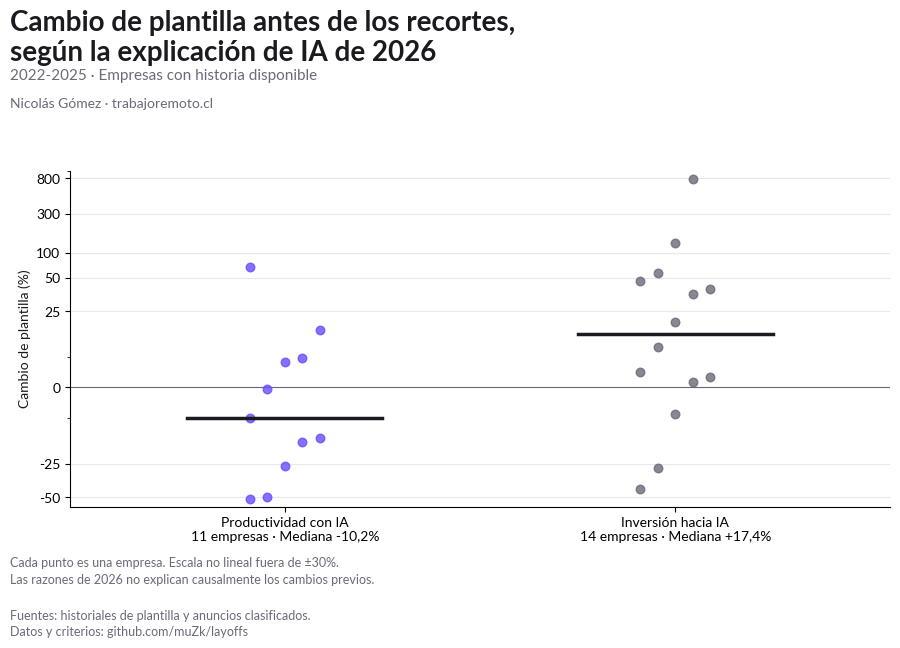

In [3]:
# DESARROLLO_COMPARACION
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display
for font in (ROOT/'notebooks/data/fonts').glob('Lato-*.ttf'):
    font_manager.fontManager.addfont(str(font))
plt.rcParams.update({'font.family':'Lato','svg.fonttype':'none','text.color':'#1A1A1F','axes.labelcolor':'#1A1A1F'})
labels={'ai_productivity':'Productividad con IA','ai_investment_reallocation':'Inversión hacia IA'}
groups={code:[r for r in hist if r['window']=='2022_2025' and code in r['codes']] for code in labels}
assert not ({r['company'] for r in groups['ai_productivity']} & {r['company'] for r in groups['ai_investment_reallocation']})
history_by_company={r['company']:r for r in json.loads((ROOT/'research/hiring/company-history.json').read_text())}
rows=[]
for code,rr in groups.items():
    for r in rr:
        observations=history_by_company[r['company']]['observations']
        start=next(o for o in observations if o['date']==r['start'])
        end=next(o for o in observations if o['date']==r['end'])
        rows.append({'Empresa':r['company'],'Razón':labels[code],'Fecha inicial':r['start'],'Plantilla inicial':start['value'],'Fecha final':r['end'],'Plantilla final':end['value'],'Cambio %':r['growth'],'Fuente inicial':start.get('source_url'),'Fuente final':end.get('source_url')})
display(pd.DataFrame(rows).sort_values(['Razón','Cambio %']))
sensitivity=[]
for label,pred in [('Pares utilizables',lambda r:True),('Ambos cierres en diciembre',lambda r:r['start'][5:7]=='12' and r['end'][5:7]=='12'),('Sin cambios de perímetro documentados',lambda r:not any(r['start']<e['date']<=r['end'] for e in r['events'])),('Sin alerta estricta de definición',lambda r:not any(q.get('strict_exclusion') for q in r['quality']))]:
    for code,rr in groups.items():
        sub=[r for r in rr if pred(r)]
        sensitivity.append({'Selección':label,'Razón':labels[code],'Empresas':len(sub),'Mediana %':statistics.median(r['growth'] for r in sub),'Redujeron plantilla':sum(r['growth']<0 for r in sub)})
display(pd.DataFrame(sensitivity))
for code,rr in groups.items():
    total=len({r['company_label'] for r in records if code in reasons[r['record_id']]})
    print(labels[code],': historia disponible',len(rr),'de',total,'empresas')
    leave=[statistics.median(r['growth'] for r in rr if r['company']!=removed['company']) for removed in rr]
    print('Mediana al retirar una empresa:',min(leave),max(leave))
# La escala symlog conserva signos y todos los puntos, incluido MARA (+786,7%).
# Su tramo central es lineal entre -30 y +30; fuera comprime extremos.
for mobile in [False,True]:
    fig,ax=plt.subplots(figsize=(6 if mobile else 10,8 if mobile else 7))
    fig.subplots_adjust(left=.16 if mobile else .12,right=.94,bottom=.25,top=.73)
    title='Cambio de plantilla antes de los recortes,\nsegún la explicación de IA de 2026'
    fig.text(.06,.96,title,va='top',fontsize=16 if mobile else 20,weight='bold')
    fig.text(.06,.86,'2022-2025 · Empresas con historia disponible',fontsize=11,color='#6A6A78')
    fig.text(.06,.82,'Nicolás Gómez · trabajoremoto.cl',fontsize=10,color='#6A6A78')
    for x,(code,rr) in enumerate(groups.items()):
        vals=sorted(r['growth'] for r in rr)
        ax.scatter([x+(i%5-2)*.045 for i in range(len(vals))],vals,color='#6A4CFF' if x==0 else '#6A6A78',s=38,zorder=3,alpha=.8)
        median=statistics.median(vals)
        ax.plot([x-.25,x+.25],[median,median],color='#1A1A1F',lw=2.5,zorder=4)

    ax.set_yscale('symlog',linthresh=30)
    ax.set_yticks([-50,-25,0,25,50,100,300,800],['-50','-25','0','25','50','100','300','800'])
    ax.set_ylim(-65,1000);ax.set_xlim(-.55,1.55)
    ax.set_xticks([0,1],['Productividad con IA\n11 empresas · Mediana -10,2%','Inversión hacia IA\n14 empresas · Mediana +17,4%'])
    ax.set_ylabel('Cambio de plantilla (%)')
    ax.axhline(0,color='#6A6A78',lw=.8);ax.grid(axis='y',color='#E7E7F0');ax.set_axisbelow(True)
    for s in ['top','right']:ax.spines[s].set_visible(False)
    note='Cada punto es una empresa. Escala no lineal fuera de ±30%.\nLas razones de 2026 no explican causalmente los cambios previos.'
    fig.text(.06,.14,note,fontsize=9,color='#6A6A78',linespacing=1.5)
    fig.text(.06,.065,'Fuentes: historiales de plantilla y anuncios clasificados.\nDatos y criterios: github.com/muZk/layoffs',fontsize=9,color='#6A6A78',linespacing=1.5)
    # Charts remain in notebook outputs; no report directory is required.
    if not mobile:display(fig)
    plt.close(fig)


<!-- DESARROLLO_COMPARACION -->
### Lectura y límites

Las empresas con explicaciones de productividad tienen una mediana de -10,2% (7 de 11 redujeron plantilla); las de inversión, +17,4% (11 de 14 crecieron). No desaparece al quitar una sola empresa. Sin embargo, exigir cierres de diciembre reduce las muestras a 8 y 7 y da medianas de -17,2% y +1,8%. El contraste es descriptivo y sensible a la composición: no debe convertirse en una regla sobre todas las empresas de cada categoría.

### Auditoría inicial del tamaño de los recortes: no publicado como hallazgo

La comprobación inicial confirma que debemos registrar explícitamente el denominador, no deducirlo de `announced_reduction`. Meta de enero figura con 2% en el dataset, mientras que la [fuente de Reality Labs](https://techcrunch.com/2026/01/14/meta-to-reportedly-lay-off-10-of-reality-labs-staff/) informa 10% de esa división. [Ocado](https://www.theguardian.com/business/2026/feb/26/ocado-to-cut-1000-jobs-in-150m-cost-cutting-drive) sí informa 5% global. No sustituimos porcentajes de una base por otra.

Esta es una revisión inicial de dos casos, no una auditoría completa de los 33 anuncios comparados. El contraste 21% frente a 10% sigue como candidato sin publicar: falta documentar empresa/división, fecha y fuente del denominador de cada registro. No se modificó la base canónica.


<!-- INDUSTRY_CHECK -->
<a id="industrias"></a>
## ¿La diferencia depende del tipo de negocio?

Se clasifican las 25 empresas de la comparación anterior según actividad, conservando `industry` original. Las fuentes y decisiones están en `research/hiring/industry-review.json`. Son familias analíticas amplias: **software y datos** incluye Intuit y Oracle, con una sensibilidad que los excluye; **plataformas y servicios digitales** incluye marketplaces, juegos, redes sociales y aplicaciones, y no equivale a una industria homogénea ni a B2C puro. El resto se muestra sin forzar contrapartes.

La clasificación utiliza descripciones corporativas consultadas el 3 de octubre de 2026, no una reconstrucción de ingresos por segmento de 2022-2025. No es un ajuste causal ni estadístico por industria. Se conservan todas las empresas y se muestran también subdivisiones con muestras demasiado pequeñas para concluir.


In [4]:
# INDUSTRY_CHECK
industry_review=json.loads((ROOT/'research/hiring/industry-review.json').read_text())
industry_map={r['company']:r for r in industry_review['companies']}
selected=[dict(r,reason_code=code) for code,rr in groups.items() for r in rr]
assert len(selected)==25 and {r['company'] for r in selected}==set(industry_map)
industry_rows=[{'Empresa':r['company'],'Razón':labels[r['reason_code']],'Industria original':industry_map[r['company']]['original_industry'],'Familia':industry_review['groups'][industry_map[r['company']]['analysis_group']],'Actividad':industry_map[r['company']]['activity'],'Cambio 2022-2025 %':r['growth'],'Fuente actividad':industry_map[r['company']]['source_url']} for r in selected]
display(pd.DataFrame(industry_rows).sort_values(['Familia','Razón','Empresa']))
industry_summary=[]
for family,label in industry_review['groups'].items():
    for code in labels:
        sub=[r for r in selected if r['reason_code']==code and industry_map[r['company']]['analysis_group']==family]
        industry_summary.append({'Familia':label,'Razón':labels[code],'Empresas':len(sub),'Mediana %':statistics.median(r['growth'] for r in sub) if sub else None,'Redujeron plantilla':sum(r['growth']<0 for r in sub) if sub else None})
display(pd.DataFrame(industry_summary))
# Sensibilidades de las decisiones fronterizas, sin reemplazar el resultado principal.
sens=[]
for name,pred in [
    ('Software sin Oracle ni Intuit',lambda m:m['analysis_group']=='software' and m['company'] not in {'Oracle','Intuit'}),
    ('Software más infraestructura',lambda m:m['analysis_group'] in {'software','infrastructure'}),
    ('Plataformas sin juegos ni seguridad familiar',lambda m:m['analysis_group']=='platforms' and m['company'] not in {'Playtika','Life360'}),
    ('Solo marketplaces e intermediación',lambda m:m['company'] in {'Angi','Upwork','Jumia','Lastminute','Groupon'}),
    ('Solo redes sociales y publicidad',lambda m:m['activity']=='Redes sociales y publicidad')]:
    for code in labels:
        sub=[r for r in selected if r['reason_code']==code and pred(industry_map[r['company']])]
        sens.append({'Selección':name,'Razón':labels[code],'Empresas':len(sub),'Mediana %':statistics.median(r['growth'] for r in sub) if sub else None,'Empresas incluidas':', '.join(r['company'] for r in sub)})
display(pd.DataFrame(sens))
# Resultados derivados visibles aquí; los insumos no se modifican.
for row in industry_summary:
    if row['Empresas']:print(row)


,Empresa,Razón,Industria original,Familia,Actividad,Cambio 2022-2025 %,Fuente actividad
4,Ocado,Productividad con IA,Food,Automatización y comercio alimentario,Automatización logística y comercio alimentario,8.220219,https://www.ocadogroup.com/
18,Cisco,Inversión hacia IA,Infrastructure,Infraestructura tecnológica,Redes e infraestructura tecnológica,3.481393,https://www.cisco.com/
22,Rackspace,Inversión hacia IA,None,Infraestructura tecnológica,Servicios de infraestructura cloud,-26.470588,https://www.rackspace.com/about
16,MARA,Inversión hacia IA,Crypto,Minería e infraestructura cripto,Minería cripto e infraestructura digital,786.666667,https://www.mara.com/
3,Block,Productividad con IA,Finance,Pagos y servicios financieros,Pagos y servicios financieros,-17.887029,https://block.xyz/
6,Coinbase,Productividad con IA,Crypto,Pagos y servicios financieros,Servicios financieros cripto,9.778271,https://www.coinbase.com/about
24,Groupon,Inversión hacia IA,None,Plataformas y servicios digitales,Marketplace de servicios y experiencias,-40.289256,https://www.sec.gov/Archives/edgar/data/149028...
21,Lastminute,Inversión hacia IA,None,Plataformas y servicios digitales,Intermediación de viajes,1.813634,https://corporate.lastminute.com/about-us/who-...
17,Life360,Inversión hacia IA,Consumer,Plataformas y servicios digitales,Aplicaciones de seguridad familiar,36.750000,https://www.life360.com/
11,Meta,Inversión hacia IA,Consumer,Plataformas y servicios digitales,Redes sociales y publicidad,-8.807613,https://www.meta.com/technologies/


,Familia,Razón,Empresas,Mediana %,Redujeron plantilla
0,Software y datos,Productividad con IA,3,18.770987,1.0
1,Software y datos,Inversión hacia IA,6,33.567046,0.0
2,Plataformas y servicios digitales,Productividad con IA,5,-25.882353,5.0
3,Plataformas y servicios digitales,Inversión hacia IA,5,1.813634,2.0
4,Pagos y servicios financieros,Productividad con IA,2,-4.054379,1.0
5,Pagos y servicios financieros,Inversión hacia IA,0,NaN,NaN
6,Infraestructura tecnológica,Productividad con IA,0,NaN,NaN
7,Infraestructura tecnológica,Inversión hacia IA,2,-11.494598,1.0
8,Minería e infraestructura cripto,Productividad con IA,0,NaN,NaN
9,Minería e infraestructura cripto,Inversión hacia IA,1,786.666667,0.0


,Selección,Razón,Empresas,Mediana %,Empresas incluidas
0,Software sin Oracle ni Intuit,Productividad con IA,3,18.770987,"C3.ai, ZoomInfo, Elastic"
1,Software sin Oracle ni Intuit,Inversión hacia IA,4,51.219946,"Autodesk, Atlassian, GitLab, SentinelOne"
2,Software más infraestructura,Productividad con IA,3,18.770987,"C3.ai, ZoomInfo, Elastic"
3,Software más infraestructura,Inversión hacia IA,8,17.357642,"Autodesk, Atlassian, Oracle, Cisco, Intuit, Gi..."
4,Plataformas sin juegos ni seguridad familiar,Productividad con IA,4,-37.941176,"Angi, Snap, Upwork, Jumia"
5,Plataformas sin juegos ni seguridad familiar,Inversión hacia IA,4,-3.496990,"Meta, Pinterest, Lastminute, Groupon"
6,Solo marketplaces e intermediación,Productividad con IA,3,-50.000000,"Angi, Upwork, Jumia"
7,Solo marketplaces e intermediación,Inversión hacia IA,2,-19.237811,"Lastminute, Groupon"
8,Solo redes sociales y publicidad,Productividad con IA,1,-0.510590,Snap
9,Solo redes sociales y publicidad,Inversión hacia IA,2,11.623281,"Meta, Pinterest"


{'Familia': 'Software y datos', 'Razón': 'Productividad con IA', 'Empresas': 3, 'Mediana %': 18.77098723975823, 'Redujeron plantilla': 1}
{'Familia': 'Software y datos', 'Razón': 'Inversión hacia IA', 'Empresas': 6, 'Mediana %': 33.56704645048203, 'Redujeron plantilla': 0}
{'Familia': 'Plataformas y servicios digitales', 'Razón': 'Productividad con IA', 'Empresas': 5, 'Mediana %': -25.882352941176467, 'Redujeron plantilla': 5}
{'Familia': 'Plataformas y servicios digitales', 'Razón': 'Inversión hacia IA', 'Empresas': 5, 'Mediana %': 1.813633520950586, 'Redujeron plantilla': 2}
{'Familia': 'Pagos y servicios financieros', 'Razón': 'Productividad con IA', 'Empresas': 2, 'Mediana %': -4.054379389362545, 'Redujeron plantilla': 1}
{'Familia': 'Infraestructura tecnológica', 'Razón': 'Inversión hacia IA', 'Empresas': 2, 'Mediana %': -11.494597839135656, 'Redujeron plantilla': 1}
{'Familia': 'Minería e infraestructura cripto', 'Razón': 'Inversión hacia IA', 'Empresas': 1, 'Mediana %': 786.6666

<!-- INDUSTRY_CHECK -->
### Qué cambia en la interpretación

En software y datos, la mediana es **+18,8% en productividad (3 empresas)** y **+33,6% en inversión (6)**. Dos de las tres empresas de productividad crecieron, igual que las seis de inversión. La lectura agregada de «productividad después de una reducción previa» no describe este subconjunto.

En plataformas y servicios digitales, la mediana es **-25,9% en productividad (5 empresas)** y **+1,8% en inversión (5)**. Las cinco de productividad redujeron plantilla; en inversión lo hicieron dos. Aquí sí se concentra el patrón de contracción previa. Son negocios diversos: no atribuimos el resultado a una industria uniforme.

**Hipótesis:** parte del contraste agregado puede reflejar distintos ciclos de negocio y la composición de los grupos. Es compatible con una continuidad del ajuste en algunas plataformas, mientras otras empresas financian nuevas prioridades después de crecer. Este cruce no distingue esas hipótesis de diferencias de tamaño, adquisiciones o situación financiera. La diferencia entre medianas sigue en el mismo sentido dentro de ambas familias, pero ya no hay descenso frente a crecimiento en software. No decimos que la industria explique toda la brecha.

La clasificación también importa: al reunir software e infraestructura, inversión queda en +17,4% (8 empresas), prácticamente igual a productividad (+18,8%; 3). Al quitar juegos y seguridad familiar de plataformas, ambas medianas son negativas (-37,9% y -3,5%; 4 y 4). Por tanto, ni el orden ni el contraste de signos resisten todas las definiciones. No elegimos una taxonomía por la fuerza del resultado. Para separar el papel de la industria harían falta más empresas comparables y clasificaciones históricas estables, además de variables de ingresos, márgenes y adquisiciones.
